# Demo pipeline

**Nota:** En este pipeline se asume que un dataset crudo ya se encuentra subido en HANA

In [24]:
import os
from dotenv import load_dotenv
import hana_ml.dataframe as dataframe
from hana_ml.algorithms.pal.preprocessing import IsolationForest
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import time, importlib, ventanas, explicacion

## 1. Lectura del archivo

In [3]:
# Load environment variables from .env file
load_dotenv()

HANA_ADDRESS = os.getenv("HANA_ADDRESS")
HANA_PORT = int(os.getenv("HANA_PORT"))
HANA_USER = os.getenv("HANA_USER")
HANA_PASSWORD = os.getenv("HANA_PASSWORD")

conn = dataframe.ConnectionContext(address = HANA_ADDRESS,
                                   port = HANA_PORT,
                                   user = HANA_USER,
                                   password = HANA_PASSWORD
                                   )
conn.connection.isconnected()

True

In [4]:
dataset = conn.table('LOGS_2026_10')

## 2. Preparación de los datos

In [5]:
cols_drop_llm = ['HTTP_STATUS_CODE', 'SERVICE_ID', 'CLIENT_IP']

cols_drop_system = [
    'LLM_ERROR_MESSAGE', 'LLM_RESPONSE_SIZE_BYTES', 'SAP_LLM_RESPONSE_SIZE',
    'SAP_LLM_RESPONSE_TIME', 'LLM_PROMPT_TOKENS', 'LLM_COMPLETION_TOKENS',
    'LLM_TOTAL_TOKENS', 'LLM_RESPONSE_TIME_MS', 'LLM_MODEL_ID', 'LLM_STATUS',
    'LLM_COST_USD', 'LLM_PROMPT_CATEGORY', 'LLM_TEMPERATURE', 'LLM_TOP_P',
    'LLM_STREAM', 'LLM_FINISH_REASON', 'LLM_PROMPT_ID', 'LLM_PROVIDER', 'LLM_PROMPT',
]

dataset = dataset.drop(['_IGNORED'])

df_llm = dataset.filter("\"_INDEX\" LIKE 'llm-logs%'").drop(cols_drop_llm)
df_system = dataset.filter("\"_INDEX\" LIKE 'sap-logs%'").drop(cols_drop_system)

print(len(df_llm.columns), len(df_system.columns))

40 24


In [6]:
WEEK_DAYS = 7
MIN_LAST_DAYS = 3   # si la última semana trae menos de 3 días, se descarta

TS_EXPR = ("TO_TIMESTAMP(REPLACE(REPLACE(\"TIMESTAMP\",'T',' '),'Z',''), "
           "'YYYY-MM-DD HH24:MI:SS.FF3')")

# t0 y t_max sobre la tabla completa (antes de separar), para que system y llm compartan semanas
r = conn.sql(f'SELECT MIN({TS_EXPR}) AS T0, MAX({TS_EXPR}) AS TMAX FROM LOGS_2026_10').collect()
t0, t_max = pd.to_datetime(r.loc[0, 'T0']), pd.to_datetime(r.loc[0, 'TMAX'])

span = t_max - t0
n_full = span // pd.Timedelta(days=WEEK_DAYS)
rest = span - n_full * pd.Timedelta(days=WEEK_DAYS)
n_weeks = n_full + (1 if rest >= pd.Timedelta(days=MIN_LAST_DAYS) else 0)

t0_sql = t0.strftime('%Y-%m-%d %H:%M:%S')
week_expr = (f"FLOOR(SECONDS_BETWEEN(TO_TIMESTAMP('{t0_sql}','YYYY-MM-DD HH24:MI:SS'), "
             f"{TS_EXPR}) / {WEEK_DAYS * 86400})")

def add_week(df):
    return df.select('*', (week_expr, 'WEEK_IDX'))

df_system = add_week(df_system)
df_llm = add_week(df_llm)

# Un DataFrame perezoso por semana (las filas con WEEK_IDX >= n_weeks quedan fuera)
system_weeks = {w: df_system.filter(f'WEEK_IDX = {w}') for w in range(n_weeks)}
llm_weeks = {w: df_llm.filter(f'WEEK_IDX = {w}') for w in range(n_weeks)}

print(f't0={t0}  t_max={t_max}  n_weeks={n_weeks}')
print('system:', {w: d.count() for w, d in system_weeks.items()})
print('llm:   ', {w: d.count() for w, d in llm_weeks.items()})

t0=2026-10-01 00:00:00  t_max=2026-10-11 23:59:59  n_weeks=2
system: {0: 1441821, 1: 809290}
llm:    {0: 959153, 1: 538547}


## 3. Generación de ventanas

In [10]:
importlib.reload(ventanas)

def make_windows(w):
    """Ventanas system y LLM de la semana w, como tablas temporales en HANA con WINDOW_INDEX."""
    win_sys = ventanas.materialize(conn, ventanas.build_system_windows(conn, system_weeks[w], df_system), '#WIN_SYSTEM')
    win_llm = ventanas.materialize(conn, ventanas.build_llm_windows(conn, llm_weeks[w]), '#WIN_LLM')
    return win_sys, win_llm

## 4. Isolation Forest

In [26]:
FEATURES_SYSTEM = [
    'TOTAL_REQUESTS', 'REQUEST_RATE_STD', 'INTERVAL_CV',
    'UNIQUE_IPS_COUNT', 'IP_ENTROPY', 'IP_TOP_SHARE',
    'ERROR_RATE_400', 'ERROR_RATE_500', 'NON_200_RATE',
    'RATIO_ERROR', 'RATIO_WARN', 'RATIO_SECURITY', 'RATIO_INFO', 'RATIO_AUDIT',
    'GET_VS_POST_RATIO',
    'JS_HTTP_STATUS_CODE', 'JS_HEADERS_HTTP_REQUEST_METHOD', 'JS_SAP_FUNCTION_LOG_TYPE',
    'JS_HEATHERS_REQUEST_PATH', 'JS_SAP_FUNCTION_APPLICATION', 'JS_SAP_SOURCE_TYPE',
    'JS_SAP_APP_ENV', 'JS_REGION_CODE', 'JS_HEADERS_CONTENT_TYPE',
]
FEATURES_LLM = [
    'TOTAL_LLM_REQUESTS', 'AVG_LLM_COST_USD', 'RATIO_INJECTION', 'AVG_TOKEN_RATIO',
    'AVG_RESPONSE_TIME_MS', 'LLM_ERROR_RATE', 'LLM_TIMEOUT_RATE', 'TEMPERATURE_VARIANCE',
    'PROMPT_CATEGORY_ENTROPY', 'STREAM_RATIO', 'AVG_PROMPT_LENGTH', 'MAX_PROMPT_LENGTH',
]

importlib.reload(explicacion)

def run_if(win, features):
    model = IsolationForest(n_estimators=250, max_samples=256, random_state=42)
    model.fit(data=win, key='WINDOW_INDEX', features=features)
    pred = model.predict(data=win, key='WINDOW_INDEX', features=features,
                         contamination=0.01, show_explainer=False)
    win_pdf = win.collect()
    r = win_pdf.merge(pred.collect(), on='WINDOW_INDEX')              # ventana + SCORE + LABEL

    an = r[r['LABEL'] == -1]
    idx = an['WINDOW_INDEX'].tolist()
    cf = explicacion.contrafactual(conn, model, win, features,
                                   an.set_index('WINDOW_INDEX')['SCORE'], idx)
    z = explicacion.zscores(win_pdf, idx, features)
    return r, cf, z

res = {s: {'r': [], 'cf': [], 'z': []} for s in ('system', 'llm')}
for w in range(n_weeks):
    win_sys, win_llm = make_windows(w)
    for stream, win, feats in (('system', win_sys, FEATURES_SYSTEM), ('llm', win_llm, FEATURES_LLM)):
        r, cf, z = run_if(win, feats)
        for df, name in ((r, 'r'), (cf, 'cf'), (z, 'z')):
            df.insert(0, 'WEEK', w)
            res[stream][name].append(df)

if_system, cf_system, z_system = (pd.concat(res['system'][k], ignore_index=True) for k in ('r', 'cf', 'z'))
if_llm, cf_llm, z_llm = (pd.concat(res['llm'][k], ignore_index=True) for k in ('r', 'cf', 'z'))

In [27]:
MAX_GAP = {'system': 3, 'llm': 3}   # en ventanas consecutivas, como en tu baseline

def agrupar_eventos(res, max_gap):
    """Marca EVENTO_ID: anomalías separadas por <= max_gap ventanas forman un evento. No cruza semanas."""
    res = res.sort_values(['WEEK', 'WINDOW_INDEX']).reset_index(drop=True)
    a = res[res['LABEL'] == -1]
    gap = a.groupby('WEEK')['WINDOW_INDEX'].diff()
    res['EVENTO_ID'] = pd.NA
    res.loc[a.index, 'EVENTO_ID'] = ((gap.isna()) | (gap > max_gap)).cumsum()
    return res

def resumen_eventos(res):
    """Una fila por evento: inicio, fin, nº de ventanas y ventana pico (mayor SCORE de anomalía)."""
    a = res[res['LABEL'] == -1]
    if a.empty:
        return pd.DataFrame()
    # En PAL el score más alto suele ser más anómalo; se confirma comparando medias.
    alto_es_anomalo = a['SCORE'].mean() >= res.loc[res['LABEL'] != -1, 'SCORE'].mean()
    pick = a.groupby('EVENTO_ID')['SCORE'].idxmax() if alto_es_anomalo else a.groupby('EVENTO_ID')['SCORE'].idxmin()
    pico = (a.loc[pick, ['EVENTO_ID', 'WEEK', 'WINDOW_START', 'SCORE']]
            .rename(columns={'WINDOW_START': 'VENTANA_PICO', 'SCORE': 'SCORE_PICO'})
            .set_index('EVENTO_ID'))
    g = a.groupby('EVENTO_ID').agg(INICIO=('WINDOW_START', 'min'), FIN=('WINDOW_START', 'max'),
                                   N_VENTANAS=('WINDOW_INDEX', 'size'))
    return g.join(pico).reset_index()

if_system = agrupar_eventos(if_system, MAX_GAP['system'])
if_llm = agrupar_eventos(if_llm, MAX_GAP['llm'])
eventos_system = resumen_eventos(if_system)
eventos_llm = resumen_eventos(if_llm)

print('System: anomalías =', (if_system['LABEL'] == -1).sum(), '| eventos =', len(eventos_system))
print('LLM:    anomalías =', (if_llm['LABEL'] == -1).sum(), '| eventos =', len(eventos_llm))
display(eventos_system); display(eventos_llm)

System: anomalías = 65 | eventos = 14
LLM:    anomalías = 65 | eventos = 59


,EVENTO_ID,INICIO,FIN,N_VENTANAS,WEEK,VENTANA_PICO,SCORE_PICO
0,1,2026-10-01 07:57:30,2026-10-01 07:57:30,1,0,2026-10-01 07:57:30,0.544224
1,2,2026-10-01 09:30:00,2026-10-01 09:40:00,5,0,2026-10-01 09:32:30,0.759521
2,3,2026-10-01 12:42:30,2026-10-01 12:57:30,7,0,2026-10-01 12:52:30,0.790703
3,4,2026-10-01 23:47:30,2026-10-02 00:05:00,8,0,2026-10-01 23:57:30,0.704218
4,5,2026-10-03 03:52:30,2026-10-03 03:52:30,1,0,2026-10-03 03:52:30,0.531256
5,6,2026-10-04 10:20:00,2026-10-04 10:22:30,2,0,2026-10-04 10:22:30,0.529673
6,7,2026-10-04 10:37:30,2026-10-04 10:37:30,1,0,2026-10-04 10:37:30,0.522355
7,8,2026-10-04 19:47:30,2026-10-04 19:47:30,1,0,2026-10-04 19:47:30,0.522278
8,9,2026-10-05 02:40:00,2026-10-05 02:40:00,1,0,2026-10-05 02:40:00,0.536473
9,10,2026-10-05 13:02:30,2026-10-05 13:35:00,14,0,2026-10-05 13:05:00,0.808383


,EVENTO_ID,INICIO,FIN,N_VENTANAS,WEEK,VENTANA_PICO,SCORE_PICO
0,1,2026-10-01 04:55:00,2026-10-01 04:55:00,1,0,2026-10-01 04:55:00,0.557197
1,2,2026-10-01 06:57:30,2026-10-01 06:57:30,1,0,2026-10-01 06:57:30,0.544263
2,3,2026-10-01 11:42:30,2026-10-01 11:42:30,1,0,2026-10-01 11:42:30,0.528095
3,4,2026-10-01 12:05:00,2026-10-01 12:05:00,1,0,2026-10-01 12:05:00,0.526537
4,5,2026-10-01 13:55:00,2026-10-01 13:55:00,1,0,2026-10-01 13:55:00,0.540300
5,6,2026-10-02 01:55:00,2026-10-02 01:55:00,1,0,2026-10-02 01:55:00,0.549293
6,7,2026-10-02 02:35:00,2026-10-02 02:35:00,1,0,2026-10-02 02:35:00,0.544689
7,8,2026-10-02 10:52:30,2026-10-02 10:52:30,1,0,2026-10-02 10:52:30,0.540895
8,9,2026-10-02 18:00:00,2026-10-02 18:00:00,1,0,2026-10-02 18:00:00,0.529783
9,10,2026-10-02 18:35:00,2026-10-02 18:35:00,1,0,2026-10-02 18:35:00,0.528420


In [28]:
# Por ventana: feature dominante (contrafactual y z-score) junto a cada resultado
if_system = if_system.merge(explicacion.dominantes_por_ventana(cf_system, z_system),
                            on=['WEEK', 'WINDOW_INDEX'], how='left')
if_llm = if_llm.merge(explicacion.dominantes_por_ventana(cf_llm, z_llm),
                      on=['WEEK', 'WINDOW_INDEX'], how='left')

# Por evento: se añade a las tablas de eventos de la celda 2
eventos_system = eventos_system.merge(explicacion.explicar_eventos(if_system, cf_system, z_system),
                                      on='EVENTO_ID', how='left')
eventos_llm = eventos_llm.merge(explicacion.explicar_eventos(if_llm, cf_llm, z_llm),
                                on='EVENTO_ID', how='left')

display(eventos_system); display(eventos_llm)

,EVENTO_ID,INICIO,FIN,N_VENTANAS,WEEK,VENTANA_PICO,SCORE_PICO,CF_FEATURE,CF_DELTA_MEDIO,CF_TOP3,Z_FEATURE,Z_VALOR_MEDIO
0,1,2026-10-01 07:57:30,2026-10-01 07:57:30,1,0,2026-10-01 07:57:30,0.544224,JS_SAP_FUNCTION_LOG_TYPE,0.021855,"JS_SAP_FUNCTION_LOG_TYPE (0.022), JS_SAP_SOURC...",JS_SAP_SOURCE_TYPE,3.175626
1,2,2026-10-01 09:30:00,2026-10-01 09:40:00,5,0,2026-10-01 09:32:30,0.759521,IP_TOP_SHARE,0.021450,"IP_TOP_SHARE (0.021), JS_SAP_FUNCTION_APPLICAT...",JS_SAP_FUNCTION_APPLICATION,8.630218
2,3,2026-10-01 12:42:30,2026-10-01 12:57:30,7,0,2026-10-01 12:52:30,0.790703,IP_ENTROPY,0.023963,"IP_ENTROPY (0.024), JS_HEADERS_HTTP_REQUEST_ME...",JS_SAP_FUNCTION_LOG_TYPE,14.456196
3,4,2026-10-01 23:47:30,2026-10-02 00:05:00,8,0,2026-10-01 23:57:30,0.704218,JS_SAP_FUNCTION_APPLICATION,0.023381,"JS_SAP_FUNCTION_APPLICATION (0.023), RATIO_ERR...",UNIQUE_IPS_COUNT,21.559249
4,5,2026-10-03 03:52:30,2026-10-03 03:52:30,1,0,2026-10-03 03:52:30,0.531256,IP_TOP_SHARE,0.033634,"IP_TOP_SHARE (0.034), JS_HEADERS_CONTENT_TYPE ...",JS_HEADERS_CONTENT_TYPE,4.168963
5,6,2026-10-04 10:20:00,2026-10-04 10:22:30,2,0,2026-10-04 10:22:30,0.529673,REQUEST_RATE_STD,0.019032,"REQUEST_RATE_STD (0.019), RATIO_AUDIT (0.018),...",REQUEST_RATE_STD,3.216411
6,7,2026-10-04 10:37:30,2026-10-04 10:37:30,1,0,2026-10-04 10:37:30,0.522355,JS_SAP_FUNCTION_LOG_TYPE,0.031092,"JS_SAP_FUNCTION_LOG_TYPE (0.031), ERROR_RATE_5...",RATIO_AUDIT,2.633714
7,8,2026-10-04 19:47:30,2026-10-04 19:47:30,1,0,2026-10-04 19:47:30,0.522278,INTERVAL_CV,0.026852,"INTERVAL_CV (0.027), RATIO_AUDIT (0.021), UNIQ...",REQUEST_RATE_STD,2.504992
8,9,2026-10-05 02:40:00,2026-10-05 02:40:00,1,0,2026-10-05 02:40:00,0.536473,JS_SAP_FUNCTION_LOG_TYPE,0.031100,"JS_SAP_FUNCTION_LOG_TYPE (0.031), JS_SAP_SOURC...",RATIO_SECURITY,3.033401
9,10,2026-10-05 13:02:30,2026-10-05 13:35:00,14,0,2026-10-05 13:05:00,0.808383,IP_TOP_SHARE,0.025629,"IP_TOP_SHARE (0.026), RATIO_ERROR (0.021), JS_...",IP_TOP_SHARE,12.429534


,EVENTO_ID,INICIO,FIN,N_VENTANAS,WEEK,VENTANA_PICO,SCORE_PICO,CF_FEATURE,CF_DELTA_MEDIO,CF_TOP3,Z_FEATURE,Z_VALOR_MEDIO
0,1,2026-10-01 04:55:00,2026-10-01 04:55:00,1,0,2026-10-01 04:55:00,0.557197,AVG_TOKEN_RATIO,0.045529,"AVG_TOKEN_RATIO (0.046), TOTAL_LLM_REQUESTS (0...",AVG_TOKEN_RATIO,4.281327
1,2,2026-10-01 06:57:30,2026-10-01 06:57:30,1,0,2026-10-01 06:57:30,0.544263,AVG_PROMPT_LENGTH,0.024982,"AVG_PROMPT_LENGTH (0.025), TOTAL_LLM_REQUESTS ...",AVG_PROMPT_LENGTH,2.155701
2,3,2026-10-01 11:42:30,2026-10-01 11:42:30,1,0,2026-10-01 11:42:30,0.528095,AVG_PROMPT_LENGTH,0.035366,"AVG_PROMPT_LENGTH (0.035), PROMPT_CATEGORY_ENT...",AVG_PROMPT_LENGTH,-2.964980
3,4,2026-10-01 12:05:00,2026-10-01 12:05:00,1,0,2026-10-01 12:05:00,0.526537,MAX_PROMPT_LENGTH,0.032564,"MAX_PROMPT_LENGTH (0.033), AVG_PROMPT_LENGTH (...",MAX_PROMPT_LENGTH,-2.603623
4,5,2026-10-01 13:55:00,2026-10-01 13:55:00,1,0,2026-10-01 13:55:00,0.540300,TOTAL_LLM_REQUESTS,0.026100,"TOTAL_LLM_REQUESTS (0.026), TEMPERATURE_VARIAN...",TEMPERATURE_VARIANCE,2.273430
5,6,2026-10-02 01:55:00,2026-10-02 01:55:00,1,0,2026-10-02 01:55:00,0.549293,AVG_PROMPT_LENGTH,0.041462,"AVG_PROMPT_LENGTH (0.041), AVG_RESPONSE_TIME_M...",AVG_RESPONSE_TIME_MS,3.812981
6,7,2026-10-02 02:35:00,2026-10-02 02:35:00,1,0,2026-10-02 02:35:00,0.544689,RATIO_INJECTION,0.056172,"RATIO_INJECTION (0.056), AVG_TOKEN_RATIO (0.03...",RATIO_INJECTION,4.057732
7,8,2026-10-02 10:52:30,2026-10-02 10:52:30,1,0,2026-10-02 10:52:30,0.540895,LLM_TIMEOUT_RATE,0.034592,"LLM_TIMEOUT_RATE (0.035), AVG_RESPONSE_TIME_MS...",LLM_TIMEOUT_RATE,3.428711
8,9,2026-10-02 18:00:00,2026-10-02 18:00:00,1,0,2026-10-02 18:00:00,0.529783,LLM_ERROR_RATE,0.048920,"LLM_ERROR_RATE (0.049), AVG_RESPONSE_TIME_MS (...",LLM_ERROR_RATE,3.865769
9,10,2026-10-02 18:35:00,2026-10-02 18:35:00,1,0,2026-10-02 18:35:00,0.528420,AVG_PROMPT_LENGTH,0.034765,"AVG_PROMPT_LENGTH (0.035), TEMPERATURE_VARIANC...",AVG_PROMPT_LENGTH,-2.728756


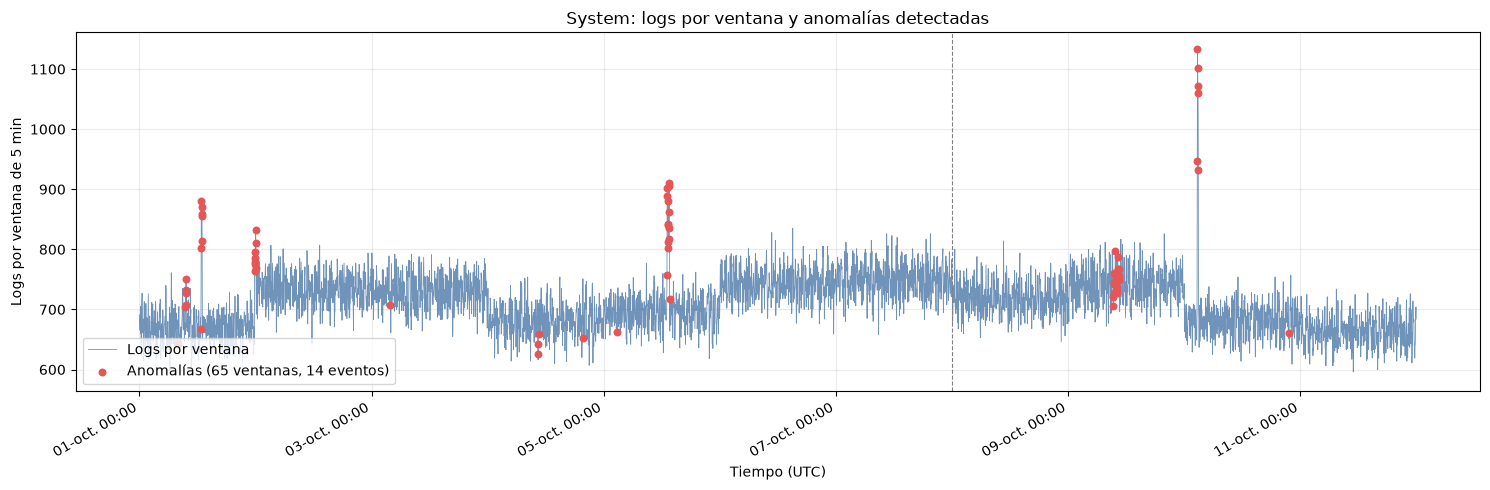

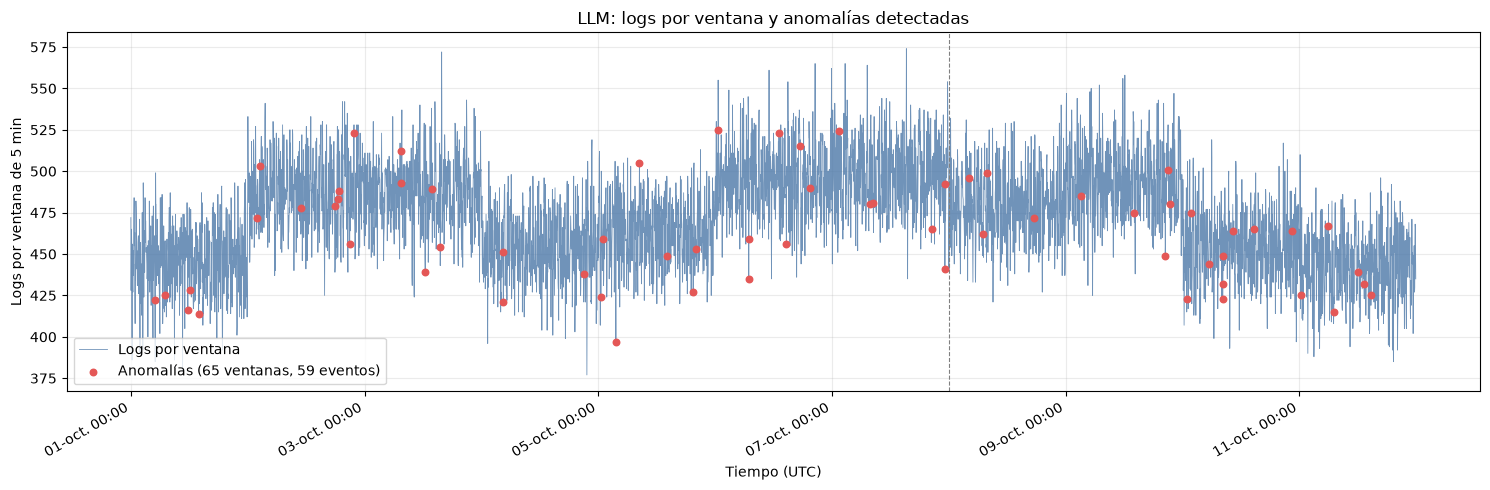

In [30]:
def graficar(res, col, titulo):
    d = res.sort_values('WINDOW_START')
    a = d[d['LABEL'] == -1]
    fig, ax = plt.subplots(figsize=(15, 5))
    ax.plot(d['WINDOW_START'], d[col], color='#4c78a8', lw=0.6, alpha=0.8, label='Logs por ventana')
    ax.scatter(a['WINDOW_START'], a[col], color='#e45756', s=22, zorder=3,
               label=f"Anomalías ({len(a)} ventanas, {a['EVENTO_ID'].nunique()} eventos)")
    for w, g in d.groupby('WEEK'):
        if w > 0:
            ax.axvline(g['WINDOW_START'].min(), color='gray', ls='--', lw=0.8)   # corte de semana
    ax.set_title(titulo)
    ax.set_xlabel('Tiempo (UTC)')
    ax.set_ylabel('Logs por ventana de 5 min')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d-%b %H:%M'))
    ax.grid(alpha=0.25)
    ax.legend(loc='lower left')
    fig.autofmt_xdate()
    fig.tight_layout()
    plt.show()

graficar(if_system, 'TOTAL_REQUESTS', 'System: logs por ventana y anomalías detectadas')
graficar(if_llm, 'TOTAL_LLM_REQUESTS', 'LLM: logs por ventana y anomalías detectadas')

## 5. Clustering Binario